# Student Lifestyle and Wellbeing Analysis

## Problem Statement

Students use digital platforms for communication, entertainment, learning, and other purposes. Their daily routines also include studying, sleeping, and physical activity. These factors may be associated with differences in stress levels and recorded mental health scores.

The purpose of this project is to analyse the available student lifestyle dataset, identify patterns through visualizations and statistical testing, and explore whether selected lifestyle variables can be used to predict recorded scores using basic machine-learning models.

## Story Behind the Dataset

This project follows the idea that student wellbeing can be explored by examining everyday lifestyle habits alongside digital-platform usage. The dataset contains demographic information, platform usage, study hours, physical activity, sleep duration, stress levels, and a numerical Mental Health Score.

The file used in this project is an augmented educational dataset. Data-quality issues, such as missing values, duplicate records, inconsistent category labels, invalid numerical values, and text noise, were introduced to practise data cleaning. The lifestyle reflection text is synthetically generated from dataset fields; it is not genuine text written by students.

Therefore, the project focuses on learning how to inspect, clean, visualize, and analyse data. The recorded score is not assumed to be a clinically validated measure, and any relationships found will not be treated as proof of cause and effect.

## Research Questions

1. What are the distributions of the main student lifestyle and wellbeing variables?
2. Is sleep duration associated with the recorded Mental Health Score?
3. Can selected numerical lifestyle variables predict the recorded score?
4. Which of the classification models tested performs best at classifying the score into relative groups?
5. Which words occur most frequently in the synthetically generated lifestyle reflections?

## Project Objectives

1. Inspect the dataset and identify data-quality issues.
2. Clean missing values, duplicates, inconsistent category labels, and invalid negative values.
3. Explore variable distributions and numerical correlations using graphs.
4. Test the relationship between sleep duration and the recorded score using Pearson correlation.
5. Compare Linear Regression and Random Forest Regression using MAE, RMSE, and R².
6. Compare Logistic Regression, Decision Tree, Random Forest, SVM, and KNN using test accuracy.
7. Demonstrate basic text preprocessing and word-frequency analysis.
8. Summarize the findings and explain the limitations of the dataset and analysis.

# 1. Understanding the Dataset

Before applying data preprocessing techniques or machine learning algorithms, it is important to understand the dataset. This helps us identify the information available, the type of variables, possible data-quality issues, and the questions that can be investigated.

In this project, we will first inspect the student lifestyle and social media dataset using basic pandas functions. We will examine its dimensions, column names, data types, summary statistics, missing values, duplicate records, and category values.

The observations from this stage will guide us in defining the project problem and selecting suitable methods for further analysis.

In [6]:

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [7]:

# Load the dataset
df = pd.read_csv("moodlens_augmented_unclean.csv")

# Display the dataset shape
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

# Display the first five records
display(df.head())



Dataset loaded successfully!
Number of rows and columns: (5015, 15)


,Source_Row_ID,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Synthetic_Lifestyle_Reflection
0,1,21.0,Male,Other,Undergraduate,Facebook,Networking,4.0,134.0,4.5,2.2,6.7,Medium,6.8,"My sleep is okay most nights, though not alway..."
1,2,23.0,Female,Other,Graduate,LinkedIn,Education,1.6,73.0,7.0,2.4,8.6,Low,7.6,"I don't spend much time on LinkedIn, mostly to..."
2,3,22.0,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166.0,4.0,1.8,6.7,Medium,7.0,"I usually get a decent amount of rest, with a ..."
3,4,18.0,Male,Other,High School,Snapchat,Entertainment,7.0,220.0,1.0,1.7,5.4,Very High,5.3,There isn't much pressure from coursework at t...
4,5,24.0,Female,Other,Graduate,Facebook,Networking,7.5,237.0,1.0,1.1,5.0,Very High,4.4,Staying active is something I make a point of ...


## 

1.1 Dataset Overview

We will begin by checking the number of records and columns and displaying a few sample records. This gives us an initial idea of the size and structure of the dataset.

In [8]:
print("Number of rows and columns:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

Number of rows and columns: (5015, 15)

First five records:


,Source_Row_ID,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Synthetic_Lifestyle_Reflection
0,1,21.0,Male,Other,Undergraduate,Facebook,Networking,4.0,134.0,4.5,2.2,6.7,Medium,6.8,"My sleep is okay most nights, though not alway..."
1,2,23.0,Female,Other,Graduate,LinkedIn,Education,1.6,73.0,7.0,2.4,8.6,Low,7.6,"I don't spend much time on LinkedIn, mostly to..."
2,3,22.0,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166.0,4.0,1.8,6.7,Medium,7.0,"I usually get a decent amount of rest, with a ..."
3,4,18.0,Male,Other,High School,Snapchat,Entertainment,7.0,220.0,1.0,1.7,5.4,Very High,5.3,There isn't much pressure from coursework at t...
4,5,24.0,Female,Other,Graduate,Facebook,Networking,7.5,237.0,1.0,1.1,5.0,Very High,4.4,Staying active is something I make a point of ...



Last five records:


,Source_Row_ID,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Synthetic_Lifestyle_Reflection
5010,4016,19.0,Female,Brazil,Undergraduate,WhatsApp,Entertainment,5.9,184.0,1.2,1.9,6.7,High,6.2,"Assignments come in waves, but I handle them o..."
5011,4429,18.0,Male,USA,High School,Instagram,Entertainment,7.0,210.0,0.7,1.4,5.8,High,4.2,I pick up my phone far more often than I'd lik...
5012,2966,22.0,Male,New Zealand,Undergraduate,Instagram,Entertainment,4.8,146.0,2.6,2.6,7.8,High,6.8,I get enough rest on most days but it isn't so...
5013,1098,22.0,Female,Bahrain,Undergraduate,LinkedIn,Education,2.8,112.0,4.3,2.3,7.1,Medium,8.0,"LinkedIn is only a small part of my day, mostl..."
5014,2643,23.0,Male,Canada,Graduate,TikTok,Entertainment,5.5,179.0,1.6,1.7,6.5,Very High,6.6,My phone use during the day is pretty typical....


## 1.2 Column Names and Data Types

Each column represents a variable that may help us understand student lifestyle patterns. However, different variables contain different kinds of information.

For example, age and sleep duration are numerical variables, while gender and the most-used social media platform are categorical variables. The synthetic reflection column contains text.

We will inspect the column names and data types to understand how the variables may be used in further analysis.

In [9]:

# Display all column names
print("Column names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

# Display data types of each column
print("\nData types:")
display(df.dtypes)


Column names:
['Source_Row_ID', 'Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night', 'Stress_Level', 'Mental_Health_Score', 'Synthetic_Lifestyle_Reflection']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5015 entries, 0 to 5014
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Source_Row_ID                   5015 non-null   int64  
 1   Age                             4815 non-null   float64
 2   Gender                          4865 non-null   str    
 3   Country                         5015 non-null   str    
 4   Academic_Level                  4865 non-null   str    
 5   Most_Used_Platform              4815 non-null   str    
 6   Purpose_Of_Use                  5015 non-null   str    
 7   Avg_Daily_Usage_Hours       

Source_Row_ID                       int64
Age                               float64
Gender                                str
Country                               str
Academic_Level                        str
Most_Used_Platform                    str
Purpose_Of_Use                        str
Avg_Daily_Usage_Hours             float64
Daily_Unlocks                     float64
Study_Hours                       float64
Physical_Activity_Hours           float64
Sleep_Hours_Per_Night             float64
Stress_Level                          str
Mental_Health_Score               float64
Synthetic_Lifestyle_Reflection        str
dtype: object

## 1.3 Understanding the Variables

Based on the column names, the variables can initially be grouped as follows:

**1. Demographic variables**
- Age
- Gender
- Country
- Academic_Level

**2. Social media usage variables**
- Most_Used_Platform
- Purpose_Of_Use
- Avg_Daily_Usage_Hours
- Daily_Unlocks

**3. Lifestyle variables**
- Study_Hours
- Physical_Activity_Hours
- Sleep_Hours_Per_Night

**4. Wellbeing-related variable**
- Stress_Level
- Mental_Health_Score

**5. Identifier and text variables**
- Source_Row_ID
- Synthetic_Lifestyle_Reflection

This grouping is based on the column names and should be confirmed by examining the actual values and dataset documentation.

The `Source_Row_ID` column is an identifier rather than a lifestyle measurement. The `Synthetic_Lifestyle_Reflection` column contains generated practice text and must not be treated as genuine statements from students.

## 1.4 Statistical Summary of the Dataset

Summary statistics help us understand the distribution of numerical variables. Measures such as mean, standard deviation, minimum, maximum, and quartiles can reveal unusual values or large differences between records.

We will also inspect the categorical variables to understand the number of unique values and the most frequent categories.

In [57]:
print("Summary of numerical variables:")
display(df.describe().T)
print("\nSummary of all variable types:")
display(df.describe(include="all").T)

Summary of numerical variables:


,count,mean,std,min,25%,50%,75%,max
Source_Row_ID,5015.0,2500.886540,1442.672840,1.0,1250.5,2502.0,3749.5,5000.0
Age,4815.0,20.797508,2.054491,-22.0,19.0,21.0,22.0,38.0
Avg_Daily_Usage_Hours,4765.0,5.110619,2.219164,1.0,3.8,5.0,6.3,81.0
Daily_Unlocks,4815.0,171.125234,44.560601,-211.0,140.0,171.0,204.0,530.0
Study_Hours,4765.0,3.010346,1.652017,-3.9,1.5,2.8,4.2,10.5
Physical_Activity_Hours,5015.0,1.749212,0.689819,-2.4,1.3,1.7,2.2,8.5
Sleep_Hours_Per_Night,4815.0,6.685358,2.274384,2.5,5.6,6.6,7.5,89.0
Mental_Health_Score,5015.0,6.232323,1.278634,3.6,5.1,6.1,7.1,9.4



Summary of all variable types:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Source_Row_ID,5015.0,NaN,NaN,NaN,2500.88654,1442.67284,1.0,1250.5,2502.0,3749.5,5000.0
Age,4815.0,NaN,NaN,NaN,20.797508,2.054491,-22.0,19.0,21.0,22.0,38.0
Gender,4865,12,Male,2536,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,5015,111,Other,1881,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Academic_Level,4865,16,Undergraduate,3499,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Most_Used_Platform,4815,44,Instagram,1063,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purpose_Of_Use,5015,20,Entertainment,2541,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Avg_Daily_Usage_Hours,4765.0,NaN,NaN,NaN,5.110619,2.219164,1.0,3.8,5.0,6.3,81.0
Daily_Unlocks,4815.0,NaN,NaN,NaN,171.125234,44.560601,-211.0,140.0,171.0,204.0,530.0
Study_Hours,4765.0,NaN,NaN,NaN,3.010346,1.652017,-3.9,1.5,2.8,4.2,10.5


# 2. Data Cleaning and Preprocessing

The dataset contains some deliberately introduced data-quality issues. Before performing exploratory data analysis and applying machine learning models, we need to inspect and correct these issues.

The cleaning process will include:
- Checking and handling missing values.
- Removing duplicate records.
- Correcting inconsistent categorical labels.
- Identifying and handling invalid numerical values.
- Checking the dataset again after cleaning.

The original dataset will be kept unchanged, and the cleaning operations will be performed on a separate copy.

In [58]:

# Create a copy for data cleaning
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)


Original dataset shape: (5015, 15)
Working dataset shape: (5015, 15)


In [59]:
print("Missing values in each column:")
display(df_clean.isnull().sum())

print("Total missing values:", df_clean.isnull().sum().sum())

print("Duplicate rows:", df_clean.duplicated().sum())

Missing values in each column:


Source_Row_ID                       0
Age                               200
Gender                            150
Country                             0
Academic_Level                    150
Most_Used_Platform                200
Purpose_Of_Use                      0
Avg_Daily_Usage_Hours             250
Daily_Unlocks                     200
Study_Hours                       250
Physical_Activity_Hours             0
Sleep_Hours_Per_Night             200
Stress_Level                      150
Mental_Health_Score                 0
Synthetic_Lifestyle_Reflection     30
dtype: int64

Total missing values: 1780
Duplicate rows: 15


In [60]:
print("Duplicate rows before cleaning:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Shape after removing duplicates:", df_clean.shape)
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Duplicate rows before cleaning: 15
Shape after removing duplicates: (5000, 15)
Duplicate rows after cleaning: 0


### 2.1 Handling Missing Values

Missing values can affect data analysis and machine learning models. In this step, we will identify missing values and handle them using suitable methods.

For numerical columns, missing values will be replaced with the median. For categorical columns, missing values will be replaced with the mode (the most frequently occurring value).

In [61]:

# Identify numerical and categorical columns
numerical_columns = df_clean.select_dtypes(include=['number']).columns
categorical_columns = df_clean.select_dtypes(include=['object', 'category', 'str']).columns

# Fill missing numerical values with the median
for column in numerical_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

# Fill missing categorical values with the mode
for column in categorical_columns:
    if df_clean[column].isnull().sum() > 0:
        df_clean[column] = df_clean[column].fillna(df_clean[column].mode()[0])

# Check missing values after cleaning
print("Missing values after cleaning:")
display(df_clean.isnull().sum())

print("Total missing values remaining:", df_clean.isnull().sum().sum())


Task was destroyed but it is pending!
task: <Task pending name='Task-1023' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-1024' coro=<Kernel.shell_main() running at C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:81: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  if any(self.check(obj) for obj in obj_iter):
Task was destroyed but it is pending!
task: <Task pending name='Task-1024' coro=<Kernel.shell_main() running at C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\ipykernel\kernelbas

Missing values after cleaning:


Source_Row_ID                     0
Age                               0
Gender                            0
Country                           0
Academic_Level                    0
Most_Used_Platform                0
Purpose_Of_Use                    0
Avg_Daily_Usage_Hours             0
Daily_Unlocks                     0
Study_Hours                       0
Physical_Activity_Hours           0
Sleep_Hours_Per_Night             0
Stress_Level                      0
Mental_Health_Score               0
Synthetic_Lifestyle_Reflection    0
dtype: int64

Total missing values remaining: 0


### 2.3 Handling Inconsistent Categorical Labels

Categorical data may contain inconsistent labels because of differences in capitalization, extra spaces, or spelling variations. For example, "Female", "female", and " Female " may represent the same category.

In this step, we will standardize the text formatting of categorical columns and inspect their unique values to identify any remaining inconsistencies.

In [16]:

# Standardize categorical labels only
categorical_columns = [
    'Gender',
    'Country',
    'Academic_Level',
    'Most_Used_Platform',
    'Purpose_Of_Use',
    'Stress_Level'
]

for column in categorical_columns:
    df_clean[column] = (
        df_clean[column]
        .astype('string')
        .str.strip()
        .str.title()
    )

# Check the categories
for column in categorical_columns:
    print("\n", column)
    print(df_clean[column].value_counts(dropna=False))



 Gender
Gender
Male      2700
Female    2300
Name: count, dtype: int64[pyarrow]

 Country
Country
Other         1880
India          389
Usa            355
Canada         230
Australia      198
              ... 
Montenegro       1
Bosnia           1
Kuwait           1
Yemen            1
Syria            1
Name: count, Length: 111, dtype: int64[pyarrow]

 Academic_Level
Academic_Level
Undergraduate    3669
Graduate          891
High School       440
Name: count, dtype: int64[pyarrow]

 Most_Used_Platform
Most_Used_Platform
Instagram    1269
Tiktok        890
Facebook      693
Linkedin      498
Youtube       472
Twitter       445
Snapchat      405
Whatsapp      170
Line           49
Vkontakte      39
Wechat         36
Kakaotalk      34
Name: count, dtype: int64[pyarrow]

 Purpose_Of_Use
Purpose_Of_Use
Entertainment    2552
Education        1094
Networking        793
News              561
Name: count, dtype: int64[pyarrow]

 Stress_Level
Stress_Level
Very High    1729
High         1397
M


### 2.4 Identifying Invalid Numerical Values

Numerical columns may contain values that are not realistic for the variable being measured. For example, negative study hours, negative sleep hours, or negative physical activity hours are not valid.

In this step, we will examine the numerical columns and identify values that may require correction. We will inspect the results before deciding how to handle them.


In [62]:

# Select numerical columns
numerical_columns = [
    'Age',
    'Avg_Daily_Usage_Hours',
    'Daily_Unlocks',
    'Study_Hours',
    'Physical_Activity_Hours',
    'Sleep_Hours_Per_Night',
    'Mental_Health_Score'
]

# Display summary statistics
print("Summary of numerical columns:")
display(df_clean[numerical_columns].describe().T)

# Count negative values in each numerical column
print("\nNegative values in numerical columns:")
display((df_clean[numerical_columns] < 0).sum())


Summary of numerical columns:


,count,mean,std,min,25%,50%,75%,max
Age,5000.0,20.80460,2.013661,-22.0,19.0,21.0,22.0,38.0
Avg_Daily_Usage_Hours,5000.0,5.10576,2.165346,1.0,3.9,5.0,6.2,81.0
Daily_Unlocks,5000.0,171.15580,43.683260,-211.0,141.0,171.0,202.0,530.0
Study_Hours,5000.0,3.00032,1.612058,-3.9,1.6,2.8,4.1,10.5
Physical_Activity_Hours,5000.0,1.74890,0.690407,-2.4,1.3,1.7,2.2,8.5
Sleep_Hours_Per_Night,5000.0,6.68116,2.231534,2.5,5.7,6.6,7.5,89.0
Mental_Health_Score,5000.0,6.23098,1.278701,3.6,5.1,6.1,7.1,9.4



Negative values in numerical columns:


Age                         3
Avg_Daily_Usage_Hours       0
Daily_Unlocks               4
Study_Hours                 4
Physical_Activity_Hours    16
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


### 2.5 Handling Invalid Numerical Values

After identifying numerical values that may be invalid, we will handle them according to the meaning of each variable. Negative values for age, daily usage hours, study hours, physical activity hours, and sleep hours are not realistic.

We will replace invalid negative values in these columns with missing values and then fill them using the median of the respective column. We will preserve the recorded Mental Health Score and inspect its range separately rather than changing it without evidence.


In [63]:

# Columns where negative values are invalid
non_negative_columns = [
    'Age',
    'Avg_Daily_Usage_Hours',
    'Daily_Unlocks',
    'Study_Hours',
    'Physical_Activity_Hours',
    'Sleep_Hours_Per_Night'
]

# Count negative values before correction
print("Negative values before correction:")
display((df_clean[non_negative_columns] < 0).sum())

# Replace negative values with missing values
for column in non_negative_columns:
    df_clean.loc[df_clean[column] < 0, column] = np.nan

# Fill newly created missing values with the column median
for column in non_negative_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

# Check again
print("\nNegative values after correction:")
display((df_clean[non_negative_columns] < 0).sum())

print("\nMissing values remaining:")
print(df_clean.isnull().sum().sum())


Negative values before correction:


Age                         3
Avg_Daily_Usage_Hours       0
Daily_Unlocks               4
Study_Hours                 4
Physical_Activity_Hours    16
Sleep_Hours_Per_Night       0
dtype: int64


Negative values after correction:


Age                        0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
dtype: int64


Missing values remaining:
0



### 2.6 Verifying the Cleaned Dataset

After handling duplicate rows, missing values, inconsistent categorical labels, and invalid negative values, we will inspect the dataset again. This step helps us check whether the cleaning operations were successful and whether any data-quality issues remain.


In [64]:

# Check the shape of the cleaned dataset
print("Cleaned dataset shape:", df_clean.shape)

# Check missing values
print("\nMissing values in each column:")
display(df_clean.isnull().sum())

print("Total missing values:", df_clean.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate rows remaining:", df_clean.duplicated().sum())

# Check data types
print("\nData types after cleaning:")
display(df_clean.dtypes)

# Display a few cleaned records
print("\nFirst five cleaned records:")
display(df_clean.head())


Cleaned dataset shape: (5000, 15)

Missing values in each column:


Source_Row_ID                     0
Age                               0
Gender                            0
Country                           0
Academic_Level                    0
Most_Used_Platform                0
Purpose_Of_Use                    0
Avg_Daily_Usage_Hours             0
Daily_Unlocks                     0
Study_Hours                       0
Physical_Activity_Hours           0
Sleep_Hours_Per_Night             0
Stress_Level                      0
Mental_Health_Score               0
Synthetic_Lifestyle_Reflection    0
dtype: int64

Total missing values: 0

Duplicate rows remaining: 0

Data types after cleaning:


Source_Row_ID                       int64
Age                               float64
Gender                                str
Country                               str
Academic_Level                        str
Most_Used_Platform                    str
Purpose_Of_Use                        str
Avg_Daily_Usage_Hours             float64
Daily_Unlocks                     float64
Study_Hours                       float64
Physical_Activity_Hours           float64
Sleep_Hours_Per_Night             float64
Stress_Level                          str
Mental_Health_Score               float64
Synthetic_Lifestyle_Reflection        str
dtype: object


First five cleaned records:


,Source_Row_ID,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Synthetic_Lifestyle_Reflection
0,1,21.0,Male,Other,Undergraduate,Facebook,Networking,4.0,134.0,4.5,2.2,6.7,Medium,6.8,"My sleep is okay most nights, though not alway..."
1,2,23.0,Female,Other,Graduate,LinkedIn,Education,1.6,73.0,7.0,2.4,8.6,Low,7.6,"I don't spend much time on LinkedIn, mostly to..."
2,3,22.0,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166.0,4.0,1.8,6.7,Medium,7.0,"I usually get a decent amount of rest, with a ..."
3,4,18.0,Male,Other,High School,Snapchat,Entertainment,7.0,220.0,1.0,1.7,5.4,Very High,5.3,There isn't much pressure from coursework at t...
4,5,24.0,Female,Other,Graduate,Facebook,Networking,7.5,237.0,1.0,1.1,5.0,Very High,4.4,Staying active is something I make a point of ...





# 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps us understand the distributions of variables and identify patterns and relationships in the dataset before applying machine learning models.

In this section, we will examine the distribution of the recorded Mental Health Score, explore its relationship with sleep duration, and study correlations among numerical variables.


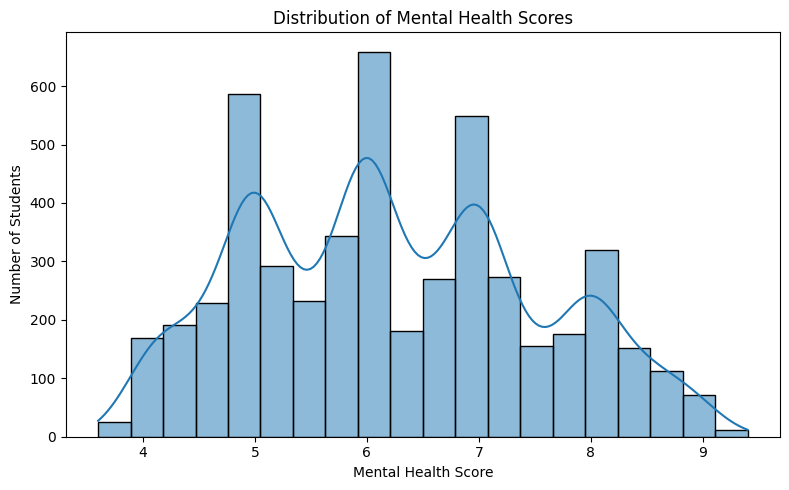

In [20]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df_clean['Mental_Health_Score'], bins=20, kde=True)
plt.title('Distribution of Mental Health Scores')
plt.xlabel('Mental Health Score')
plt.ylabel('Number of Students')
plt.tight_layout()
plt.show()



### 3.1 Sleep Duration and Mental Health Score

Sleep is one of the lifestyle variables recorded in the dataset. A scatter plot can help us examine whether sleep duration and the recorded Mental Health Score show any visible relationship.



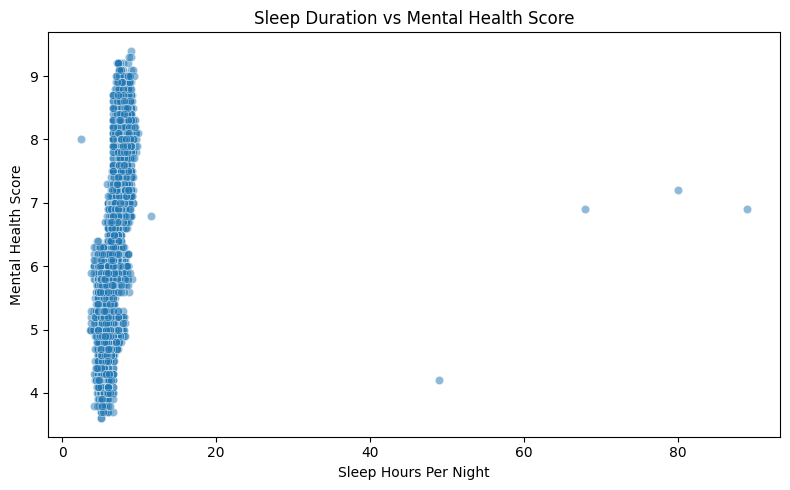

In [65]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x='Sleep_Hours_Per_Night',
    y='Mental_Health_Score',
    alpha=0.5
)

plt.title('Sleep Duration vs Mental Health Score')
plt.xlabel('Sleep Hours Per Night')
plt.ylabel('Mental Health Score')
plt.tight_layout()
plt.show()



### 3.2 Correlation among Numerical Variables

Correlation measures the strength and direction of a linear relationship between two numerical variables. A correlation heatmap helps us identify variables that may be related to the recorded Mental Health Score and to each other.


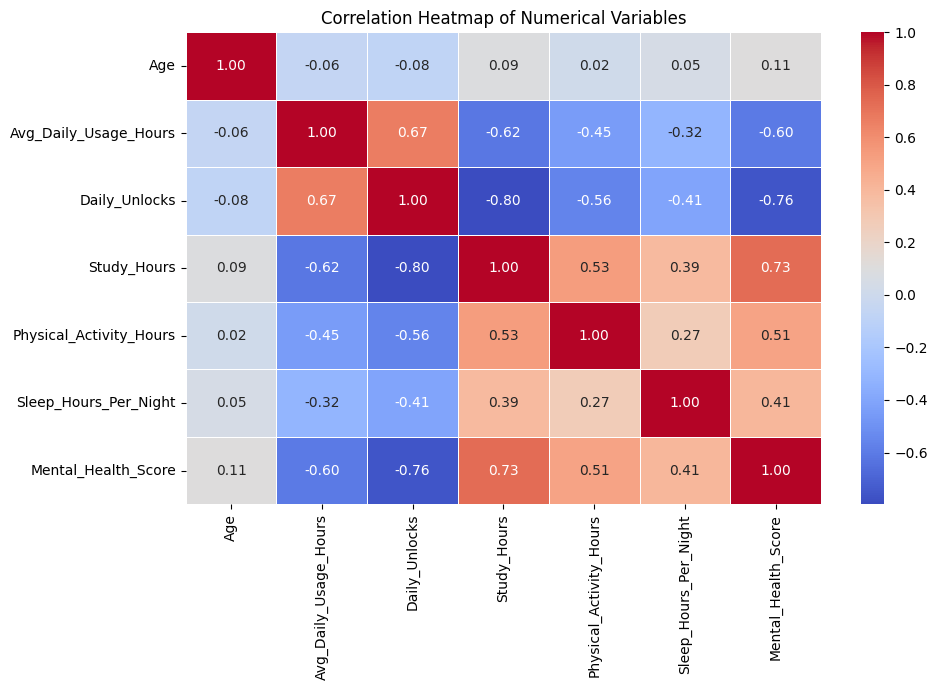

In [66]:

# Select numerical columns, excluding the row identifier
numerical_data = df_clean.select_dtypes(include=['number']).drop(
    columns=['Source_Row_ID'], errors='ignore'
)

# Calculate correlation
correlation_matrix = numerical_data.corr()

# Plot heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()


# 4. Hypothesis Testing

Hypothesis testing helps us determine whether an observed relationship in the dataset is statistically significant.

In this project, the Pearson correlation test is used to examine the relationship between sleep duration and the recorded Mental Health Score.

**Null Hypothesis (H₀):** There is no linear correlation between sleep duration and the recorded Mental Health Score.

**Alternative Hypothesis (H₁):** There is a linear correlation between sleep duration and the recorded Mental Health Score.

A significance level of 0.05 is used.

In [23]:
from scipy.stats import pearsonr

# Select the two columns and remove missing values
sleep_score_data = df_clean[
    ['Sleep_Hours_Per_Night', 'Mental_Health_Score']
].dropna()

# Perform Pearson correlation test
r, p_value = pearsonr(
    sleep_score_data['Sleep_Hours_Per_Night'],
    sleep_score_data['Mental_Health_Score']
)

print("Correlation coefficient:", round(r, 3))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Reject H0: The relationship is statistically significant.")
else:
    print("Fail to reject H0: The relationship is not statistically significant.")

Correlation coefficient: 0.408
P-value: 0.0
Reject H0: The relationship is statistically significant.


# 5. Machine Learning Models

## 5.1 Regression Analysis

Regression is used to predict a numerical value. In this project, regression models are used to predict the recorded Mental Health Score using student lifestyle and demographic variables.

Two models, Linear Regression and Random Forest Regression, are compared using MAE, RMSE, and R² score.

In [67]:
from sklearn.model_selection import train_test_split

# Select input features
X = df_clean[
    [
        'Age',
        'Avg_Daily_Usage_Hours',
        'Daily_Unlocks',
        'Study_Hours',
        'Physical_Activity_Hours',
        'Sleep_Hours_Per_Night'
    ]
]

# Select target variable
y = df_clean['Mental_Health_Score']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 6)
Testing data: (1000, 6)


In [68]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create models
lr_model = LinearRegression()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Train models
lr_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# Make predictions
lr_pred = lr_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regression'],
    'MAE': [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    'R2 Score': [
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred)
    ]
})

display(results.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.596,0.744,0.681
1,Random Forest Regression,0.437,0.570,0.813


### 5.2 Actual vs Predicted Scores

This section compares the actual Mental Health Scores with the scores predicted by the regression models. It helps us understand how closely the predictions match the actual values.

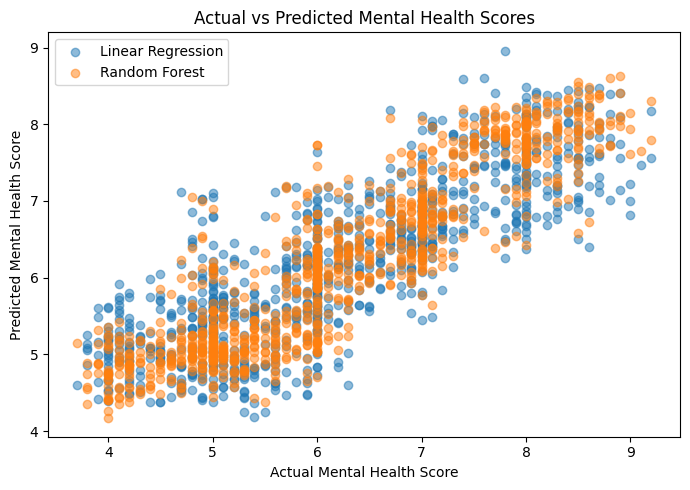

In [69]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, lr_pred, alpha=0.5, label='Linear Regression')
plt.scatter(y_test, rf_pred, alpha=0.5, label='Random Forest')

plt.xlabel('Actual Mental Health Score')
plt.ylabel('Predicted Mental Health Score')
plt.title('Actual vs Predicted Mental Health Scores')
plt.legend()
plt.tight_layout()
plt.show()

### 5.3 Regression Model Comparison and Interpretation

The regression models are compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score. MAE and RMSE measure prediction errors, while R² indicates how well the model fits the observed scores. The results are used to identify the better-performing regression model on the test data.

In [71]:
 # Display the regression model comparison
display(results.round(3))

# Identify the model with the highest R2 score
best_regression = results.loc[results['R2 Score'].idxmax()]

print("Best Regression Model:", best_regression['Model'])
print("MAE:", round(best_regression['MAE'], 3))
print("RMSE:", round(best_regression['RMSE'], 3))
print("R2 Score:", round(best_regression['R2 Score'], 3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.596,0.744,0.681
1,Random Forest Regression,0.437,0.570,0.813


Best Regression Model: Random Forest Regression
MAE: 0.437
RMSE: 0.57
R2 Score: 0.813


## 5.4 Classification Analysis

Classification predicts a category instead of a numerical value. In this project, the recorded Mental Health Score is divided into three relative groups: Lower, Middle, and Higher. Multiple classification models are compared to identify which performs best on the test data.

In [27]:
# Divide the score into three groups
df_clean['Score_Category'] = pd.qcut(
    df_clean['Mental_Health_Score'],
    q=3,
    labels=['Lower', 'Middle', 'Higher'],
    duplicates='drop'
)

print(df_clean['Score_Category'].value_counts())

Score_Category
Lower     1725
Middle    1687
Higher    1588
Name: count, dtype: int64


In [28]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

X_class = df_clean[
    [
        'Age',
        'Avg_Daily_Usage_Hours',
        'Daily_Unlocks',
        'Study_Hours',
        'Physical_Activity_Hours',
        'Sleep_Hours_Per_Night'
    ]
]

y_class = df_clean['Score_Category']

# Convert category labels into numbers
le = LabelEncoder()
y_encoded = le.fit_transform(y_class)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train_c.shape)
print("Testing data:", X_test_c.shape)
print("Class labels:", le.classes_)

Training data: (4000, 6)
Testing data: (1000, 6)
Class labels: ['Higher' 'Lower' 'Middle']


### 6.1 Logistic Regression

Logistic Regression is a classification algorithm used to predict the category of a record. The model is trained on the training data and evaluated using the test data.

In [72]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr_classifier = LogisticRegression(max_iter=1000)

lr_classifier.fit(X_train_scaled, y_train_c)

lr_class_pred = lr_classifier.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test_c, lr_class_pred)

print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.759


### 6.2 Decision Tree Classifier

A Decision Tree classifies records using decision rules based on feature values.

In [73]:
from sklearn.tree import DecisionTreeClassifier

dt_classifier = DecisionTreeClassifier(random_state=42)

dt_classifier.fit(X_train_c, y_train_c)

dt_class_pred = dt_classifier.predict(X_test_c)

dt_accuracy = accuracy_score(y_test_c, dt_class_pred)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.757


###  Decision Tree Visualization

A Decision Tree visualization shows how the trained classifier makes decisions by splitting the data according to feature values. The diagram helps us understand the decision rules used to classify records into the Lower, Middle, and Higher score categories. The tree is displayed up to a depth of three for easier interpretation.

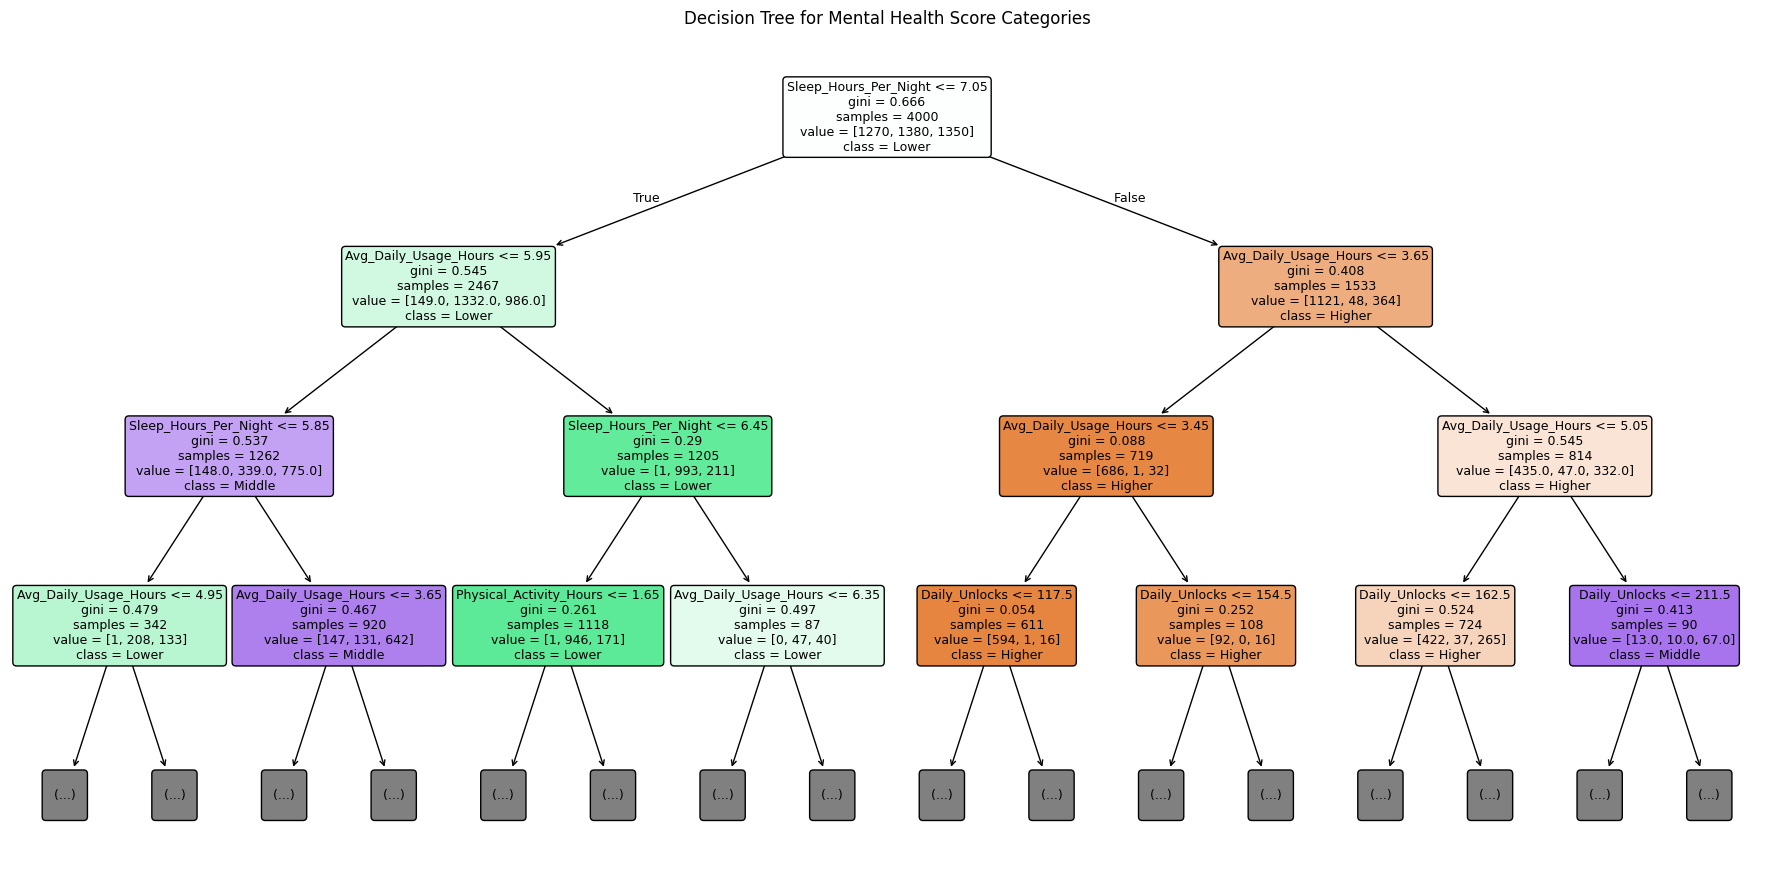

In [74]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 9))

plot_tree(
    dt_classifier,
    feature_names=X_class.columns,
    class_names=[str(c) for c in le.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree for Mental Health Score Categories")
plt.tight_layout()
plt.show()

### 6.3 Random Forest Classifier

Random Forest uses multiple decision trees to make classification predictions. Their combined predictions are used to determine the final category.

In [75]:
from sklearn.ensemble import RandomForestClassifier

rf_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_classifier.fit(X_train_c, y_train_c)

rf_class_pred = rf_classifier.predict(X_test_c)

rf_accuracy = accuracy_score(y_test_c, rf_class_pred)

print("Random Forest Accuracy:", rf_accuracy)



Random Forest Accuracy: 0.814


### 6.4 Support Vector Machine

Support Vector Machine separates categories by finding decision boundaries between them. Feature scaling is used because SVM is sensitive to differences in feature scales.

In [76]:
from sklearn.svm import SVC

svm_classifier = SVC()

svm_classifier.fit(X_train_scaled, y_train_c)

svm_class_pred = svm_classifier.predict(X_test_scaled)

svm_accuracy = accuracy_score(y_test_c, svm_class_pred)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.787


### 6.5 K-Nearest Neighbors

KNN classifies a record based on the categories of its nearest data points. Feature scaling is used so that features with larger numerical values do not dominate the distance calculation.

In [77]:
from sklearn.neighbors import KNeighborsClassifier

knn_classifier = KNeighborsClassifier()

knn_classifier.fit(X_train_scaled, y_train_c)

knn_class_pred = knn_classifier.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test_c, knn_class_pred)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.773


In [38]:
classification_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'KNN'
    ],
    'Accuracy': [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        svm_accuracy,
        knn_accuracy
    ]
})

classification_results = classification_results.sort_values(
    by='Accuracy',
    ascending=False
)

display(classification_results.round(3))

,Model,Accuracy
2,Random Forest,0.814
3,SVM,0.787
4,KNN,0.773
0,Logistic Regression,0.759
1,Decision Tree,0.757


### Classification Model Comparison

The accuracy of five classification models is compared to identify which model performs best on the testing dataset. Accuracy measures the proportion of correctly classified records. The model with the highest accuracy will be selected for further evaluation.

### 6.6 Classification Accuracy Visualization

A bar chart is used to compare the test accuracy of the five classification models. This visualization makes it easier to compare their performance and identify the model with the highest accuracy.

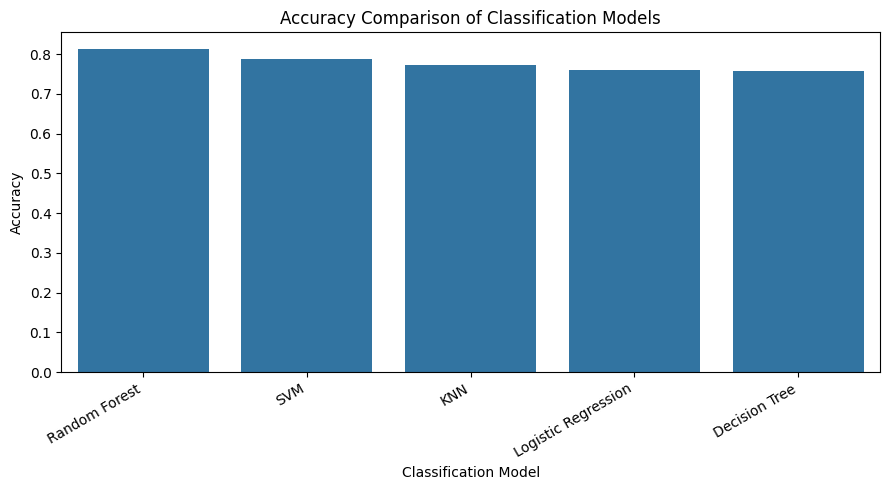

In [78]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=classification_results,
    x='Model',
    y='Accuracy'
)

plt.title('Accuracy Comparison of Classification Models')
plt.xlabel('Classification Model')
plt.ylabel('Accuracy')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 6.7 Confusion Matrix and Classification Report

The best-performing classifier, selected according to test accuracy, is evaluated using a confusion matrix and classification report. The confusion matrix displays correct and incorrect predictions for each category, while the classification report provides precision, recall, F1-score, and support.

Best Classification Model: Random Forest


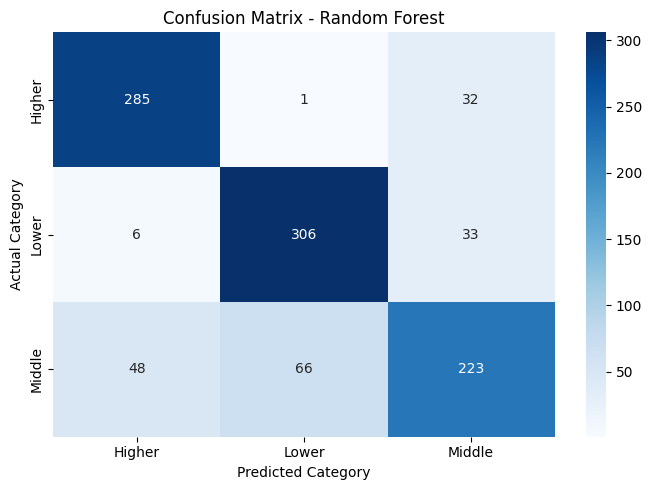

              precision    recall  f1-score   support

      Higher       0.84      0.90      0.87       318
       Lower       0.82      0.89      0.85       345
      Middle       0.77      0.66      0.71       337

    accuracy                           0.81      1000
   macro avg       0.81      0.81      0.81      1000
weighted avg       0.81      0.81      0.81      1000



In [79]:
from sklearn.metrics import confusion_matrix, classification_report

# Select the best model
best_model_name = classification_results.iloc[0]['Model']

print("Best Classification Model:", best_model_name)

# Get predictions from the best model
if best_model_name == 'Logistic Regression':
    best_predictions = lr_class_pred
elif best_model_name == 'Decision Tree':
    best_predictions = dt_class_pred
elif best_model_name == 'Random Forest':
    best_predictions = rf_class_pred
elif best_model_name == 'SVM':
    best_predictions = svm_class_pred
else:
    best_predictions = knn_class_pred

# Confusion Matrix
cm = confusion_matrix(y_test_c, best_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.title('Confusion Matrix - ' + best_model_name)
plt.tight_layout()
plt.show()

# Classification Report
print(classification_report(
    y_test_c,
    best_predictions,
    target_names=le.classes_
))

# 7. NLP Demonstration

Natural Language Processing (NLP) is a field of Artificial Intelligence that helps computers process and analyze human language. In this project, NLP techniques are demonstrated on the Synthetic_Lifestyle_Reflection column to explore common words and themes in lifestyle-related text.

The reflection sentences are synthetically generated for educational analysis. Therefore, the results demonstrate text-processing techniques and should not be interpreted as real student opinions or clinical findings.

## 7.1 Selecting and Inspecting Text Data

The first step is to select the text column and inspect a few records. This helps us understand the type of text that will be analyzed and identify any missing entries.

In [80]:
text_data = df_clean['Synthetic_Lifestyle_Reflection'].dropna()

print("Total text records:", len(text_data))
print("\nSample text records:")
display(text_data.head())

Total text records: 5000

Sample text records:


0    My sleep is okay most nights, though not alway...
1    I don't spend much time on LinkedIn, mostly to...
2    I usually get a decent amount of rest, with a ...
3    There isn't much pressure from coursework at t...
4    Staying active is something I make a point of ...
Name: Synthetic_Lifestyle_Reflection, dtype: str

## 7.2 Text Preprocessing

Text preprocessing prepares raw text for analysis by converting it to lowercase and removing punctuation, numbers, and extra spaces. This helps standardize the text so that words written in different forms can be counted consistently.

In [81]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

cleaned_text = text_data.apply(clean_text)

print("Original text:")
print(text_data.iloc[0])

print("\nCleaned text:")
print(cleaned_text.iloc[0])

Original text:
My sleep is okay most nights, though not always consistent. Exercise has fallen off my routine lately. Lately, my phone stays in my bag for long stretches during the day. I'd say my Facebook habits are pretty average, mostly to keep conversations going. Some days feel easier than others.

Cleaned text:
my sleep is okay most nights though not always consistent exercise has fallen off my routine lately lately my phone stays in my bag for long stretches during the day id say my facebook habits are pretty average mostly to keep conversations going some days feel easier than others


## 7.3 Word Frequency Analysis

Word frequency analysis identifies the words that occur most often in the text. Common English words such as "the", "and", and "is" may dominate the results, so these stopwords are removed before counting the remaining words.

In [50]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from collections import Counter

all_words = ' '.join(cleaned_text).split()

filtered_words = [
    word for word in all_words
    if word not in ENGLISH_STOP_WORDS
]

word_counts = Counter(filtered_words)

top_words = pd.DataFrame(
    word_counts.most_common(15),
    columns=['Word', 'Frequency']
)

display(top_words)

,Word,Frequency
0,phone,2989
1,day,2353
2,days,2208
3,routine,2142
4,time,1928
5,sleep,1795
6,im,1743
7,use,1607
8,feel,1465
9,things,1399


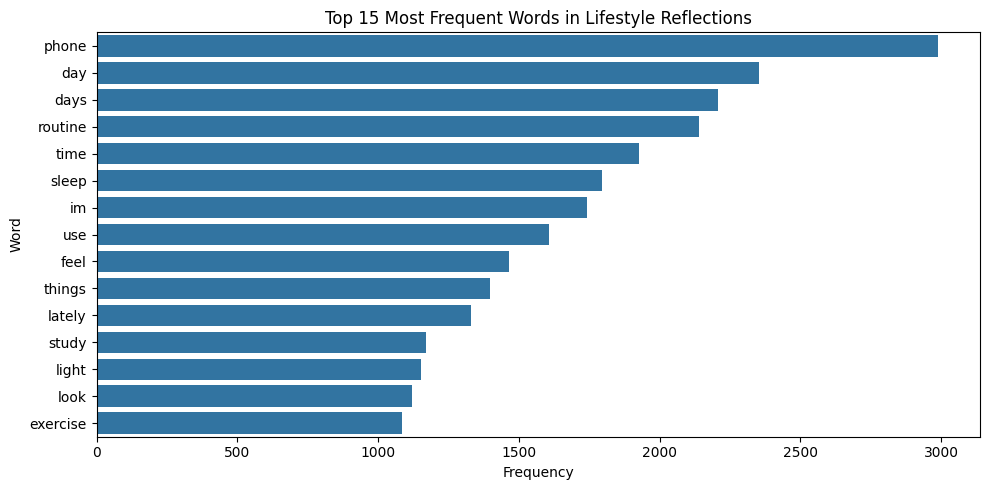

In [51]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_words,
    x='Frequency',
    y='Word'
)

plt.title('Top 15 Most Frequent Words in Lifestyle Reflections')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.show()

## 7.4 Word Cloud Visualization

A word cloud represents frequently occurring words visually. Words with higher frequencies generally appear larger, making common terms easier to identify at a glance.

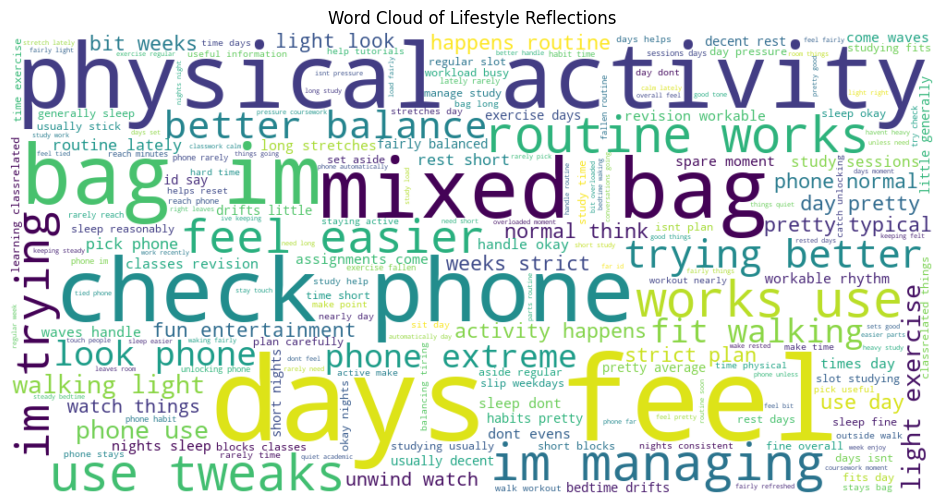

In [53]:
from wordcloud import WordCloud

text_for_cloud = ' '.join(filtered_words)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(text_for_cloud)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Lifestyle Reflections')
plt.show()

# 8. Overall Findings and Model Comparison

This section summarizes the main findings from Exploratory Data Analysis, hypothesis testing, regression, classification, and the NLP demonstration. The model comparisons help identify which tested models performed better on the selected evaluation metrics.

## 8.1 Regression Model Comparison

Linear Regression and Random Forest Regression are compared using MAE, RMSE, and R² score. Lower MAE and RMSE indicate smaller prediction errors, while a higher R² score generally indicates a better fit to the test data.

In [82]:
display(results.round(3))

best_regression = results.loc[results['R2 Score'].idxmax()]

print("Best regression model by R² score:",
      best_regression['Model'])
print("MAE:", round(best_regression['MAE'], 3))
print("RMSE:", round(best_regression['RMSE'], 3))
print("R² score:", round(best_regression['R2 Score'], 3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.596,0.744,0.681
1,Random Forest Regression,0.437,0.570,0.813


Best regression model by R² score: Random Forest Regression
MAE: 0.437
RMSE: 0.57
R² score: 0.813


## 8.2 Classification Model Comparison

The classification models are compared using accuracy. The model with the highest test accuracy is identified, while its precision, recall, F1-score, and confusion matrix are examined in Section 7.8 to understand its performance in more detail.

In [83]:
display(classification_results.round(3))

best_classification = classification_results.iloc[0]

print("Best classification model by accuracy:",
      best_classification['Model'])
print("Test accuracy:",
      round(best_classification['Accuracy'], 3))

,Model,Accuracy
2,Random Forest,0.814
3,SVM,0.787
4,KNN,0.773
0,Logistic Regression,0.759
1,Decision Tree,0.757


Best classification model by accuracy: Random Forest
Test accuracy: 0.814


## 8.3 Summary of EDA, Hypothesis Testing, and NLP

The EDA visualizations describe the distribution of Mental Health Scores, the relationship between sleep duration and scores, and correlations among numerical variables. Pearson's correlation test evaluates whether the linear relationship between sleep duration and Mental Health Score is statistically significant. NLP word-frequency analysis identifies commonly occurring terms in the synthetic lifestyle reflections.

In [57]:
print("HYPOTHESIS TEST")
print("Sleep-score correlation:", round(r, 3))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Result: Statistically significant linear association.")
else:
    print("Result: No statistically significant linear association detected.")

print("\nTOP WORDS IN TEXT")
display(top_words.head(10))

HYPOTHESIS TEST
Sleep-score correlation: 0.408
P-value: 0.0
Result: Statistically significant linear association.

TOP WORDS IN TEXT


,Word,Frequency
0,phone,2989
1,day,2353
2,days,2208
3,routine,2142
4,time,1928
5,sleep,1795
6,im,1743
7,use,1607
8,feel,1465
9,things,1399


# 9. Limitations and Future Scope

## 9.1 Limitations

1. The dataset is an augmented educational dataset, so its results may not represent the wider student population.
2. The Mental Health Score is analyzed as a recorded numerical variable and should not be treated as a clinically validated assessment.
3. The regression models use selected numerical lifestyle features; other demographic and categorical information is not included in these models.
4. The reflection sentences are synthetically generated. Their word frequencies cannot be treated as genuine student opinions or reliable evidence of emotional state.
5. Relationships identified through correlation and predictive models do not establish causation.
6. Missing values were handled during preprocessing before the train-test split. This may introduce some data leakage because imputation statistics can reflect information from the test set.

## 9.2 Future Scope

1. Evaluate the approach on a larger, independently collected and representative dataset.
2. Include additional relevant features and compare their contribution to model performance.
3. Fit preprocessing steps using training data only to reduce data leakage.
4. Use authentic, ethically collected text responses if future research requires sentiment or text-classification analysis.
5. Evaluate models using additional metrics and validation methods to assess whether their performance generalizes to unseen data.

# 10. Conclusion

This project analyzed student lifestyle and wellbeing data through data cleaning, exploratory data analysis, hypothesis testing, regression, classification, and a basic NLP demonstration.

Data preprocessing was used to address missing values, duplicate records, inconsistent category labels, and invalid numerical values. EDA was used to examine score distributions, the relationship between sleep duration and recorded Mental Health Scores, and correlations among numerical variables. Pearson's correlation test was used to evaluate the statistical significance of the linear association between sleep duration and the recorded score.

Linear Regression and Random Forest Regression were compared using MAE, RMSE, and R² score. Multiple classification models were compared using test accuracy, with a confusion matrix and classification report used for further evaluation. The NLP demonstration explored word frequencies in synthetically generated lifestyle reflections.

Overall, the project demonstrates how data analysis and machine learning can be applied to explore patterns in student lifestyle data. The findings should be interpreted cautiously because the dataset is augmented, the reflection text is synthetic, and observed associations do not establish causation. The project provides a foundation for further analysis using representative data and more rigorous model evaluation.